# Stage 6 – Model Development

## Water Point Operational Status Prediction

This notebook develops and compares multiple machine-learning algorithms for predicting the operational status of waterpoints.

Four baseline classification algorithms are evaluated:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Linear Support Vector Machine

Model comparison is performed using stratified cross-validation on the training dataset.

Because the target variable is imbalanced, model performance is evaluated using multiple metrics, with particular emphasis on Macro F1-score rather than accuracy alone.

The independent test dataset is preserved for later final-model evaluation and is not used for baseline model selection.

## 1. Import Required Libraries

The required libraries are imported for preprocessing, model development, stratified cross-validation, performance evaluation, and result comparison.

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict

print("Model development libraries imported successfully.")

Model development libraries imported successfully.


## 2. Load the Prepared Modelling Data

The compact modelling datasets produced during Stage 4 are loaded.

These datasets contain the 18 selected model-level predictors together with the target variable.

The training dataset will be used for model development and cross-validation. The independent testing dataset will remain untouched until final model evaluation.

In [2]:
train_path = "../data/processed/train_model_data.csv"
test_path = "../data/processed/test_model_data.csv"

train_data = pd.read_csv(train_path)
test_data = pd.read_csv(test_path)

print("Training data shape:", train_data.shape)
print("Testing data shape :", test_data.shape)

display(train_data.head())

Training data shape: (47520, 19)
Testing data shape : (11880, 19)


,amount_tsh,gps_height,longitude,latitude,population,basin,region,public_meeting,scheme_management,permit,management_group,payment_type,extraction_type_class,quality_group,quantity,source_type,waterpoint_type_group,waterpoint_age,status_group
0,0.0,0,33.542898,-9.174777,0,Lake Nyasa,Mbeya,Yes,VWC,NaN,user-group,never pay,gravity,good,insufficient,spring,communal standpipe,NaN,functional
1,500.0,2049,34.665760,-9.308548,175,Rufiji,Iringa,Yes,WUA,Yes,user-group,monthly,gravity,good,enough,spring,communal standpipe,3.0,functional
2,25.0,290,38.238568,-6.179919,2300,Wami / Ruvu,Pwani,Yes,VWC,No,user-group,per bucket,handpump,salty,insufficient,shallow well,hand pump,1.0,functional
3,0.0,0,30.716727,-1.289055,0,Lake Victoria,Kagera,Yes,NaN,Yes,user-group,never pay,other,good,enough,shallow well,other,NaN,non functional
4,0.0,0,35.389331,-6.399942,0,Internal,Dodoma,Yes,VWC,Yes,user-group,per bucket,motorpump,good,enough,borehole,communal standpipe,NaN,functional


### 2.1 Separate Predictors and Target

The target variable `status_group` is separated from the predictor variables in both the training and testing datasets.

The testing dataset is retained only for final evaluation and will not participate in baseline model selection.

In [3]:
X_train_model = train_data.drop(
    columns=["status_group"]
)

y_train_model = train_data["status_group"]

X_test_model = test_data.drop(
    columns=["status_group"]
)

y_test_model = test_data["status_group"]

print("X_train:", X_train_model.shape)
print("y_train:", y_train_model.shape)

print("X_test :", X_test_model.shape)
print("y_test :", y_test_model.shape)

X_train: (47520, 18)
y_train: (47520,)
X_test : (11880, 18)
y_test : (11880,)


In [4]:
class_distribution = pd.DataFrame({
    "Count": y_train_model.value_counts(),
    "Percentage": (
        y_train_model
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
})

display(class_distribution)

,Count,Percentage
status_group,,
functional,25807,54.31
non functional,18259,38.42
functional needs repair,3454,7.27


## 3. Load the Preprocessing Definition

The preprocessing transformer created during Stage 4 is loaded.

For cross-validation, an unfitted clone of this transformer will be placed inside each model pipeline. This ensures that imputation, scaling, and categorical encoding are learned independently within each training fold rather than from the complete training dataset.

In [5]:
preprocessor_path = "../models/preprocessor.joblib"

saved_preprocessor = joblib.load(
    preprocessor_path
)

print("Preprocessor loaded successfully.")

Preprocessor loaded successfully.


## 4. Define Baseline Machine-Learning Algorithms

Four classification algorithms representing different modelling approaches are selected for baseline comparison.

### Logistic Regression

Logistic Regression provides a simple linear classification baseline. It helps determine how effectively the waterpoint status classes can be separated using linear relationships between the processed predictor variables.

### Decision Tree

Decision Tree is a nonlinear classification algorithm that recursively divides the feature space according to decision rules. It can capture nonlinear relationships and interactions between predictors and provides an interpretable tree-based baseline.

### Random Forest

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees. Using many trees generally improves generalisation and reduces the instability and overfitting associated with a single decision tree.

### XGBoost

XGBoost is a gradient-boosting ensemble algorithm that builds decision trees sequentially. Each new tree attempts to correct errors made by the previous trees.

It is well suited to structured tabular datasets and can model complex nonlinear relationships and interactions between features.

XGBoost is included as a stronger ensemble baseline alongside Logistic Regression, Decision Tree, and Random Forest.

Baseline model configurations are initially used so that model performance can be compared before hyperparameter optimization.

### 4.1 Encode the Target Classes

The target variable contains three textual class labels. These labels are converted into numerical class identifiers for compatibility with the machine-learning algorithms, particularly XGBoost.

The encoder is fitted using only the training target. The resulting integers represent class identifiers and do not imply any ranking between the target classes.

In [8]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(
    y_train_model
)

y_test_encoded = label_encoder.transform(
    y_test_model
)

print("Target class mapping:")

for class_name, encoded_value in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(f"{class_name} -> {encoded_value}")

Target class mapping:
functional -> 0
functional needs repair -> 1
non functional -> 2


### 4.2 Configure the Baseline Models

Each algorithm is configured using default or near-default parameters.

Hyperparameter tuning is intentionally not performed during baseline model development. This allows the original performance of each modelling approach to be measured before optimization.

In [9]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    )
}

print("Number of baseline models:", len(models))

for model_name in models:
    print("-", model_name)

Number of baseline models: 4
- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost


## 5. Validation Strategy

A 5-fold Stratified K-Fold cross-validation strategy is used for baseline model evaluation.

Stratification preserves approximately the same target-class proportions within every fold. This is particularly important because the `functional needs repair` class is substantially less frequent than the other two target classes.

During each fold:

1. Four folds are used for training.
2. The preprocessing transformer is fitted only on those training folds.
3. The machine-learning model is trained using the transformed training folds.
4. The remaining fold is transformed using the fitted preprocessing transformer and used for validation.

This process is repeated five times so that every training observation is used for validation once.

The independent test dataset is not used during cross-validation or baseline model selection.

In [10]:
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation strategy:")
print(cv_strategy)

Cross-validation strategy:
StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


## 6. Evaluation Metrics

Multiple evaluation metrics are used because accuracy alone may provide a misleading assessment when target classes are imbalanced.

The following metrics are used:

- **Accuracy** – the proportion of all predictions that are correct.
- **Macro F1-score** – calculates the F1-score independently for every class and gives each class equal importance.
- **Weighted F1-score** – calculates class-specific F1-scores while accounting for the number of observations in each class.
- **Macro Recall** – calculates recall separately for every class and gives each class equal importance.

Macro F1-score is used as the primary model-comparison metric because it gives equal importance to `functional`, `functional needs repair`, and `non functional`, preventing the minority class from being overshadowed by the majority classes.

In [11]:
scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted",
    "recall_macro": "recall_macro"
}

print("Evaluation metrics:")

for metric in scoring:
    print("-", metric)

Evaluation metrics:
- accuracy
- f1_macro
- f1_weighted
- recall_macro


## 7. Create Complete Model Pipelines

Each machine-learning algorithm is combined with an unfitted copy of the Stage 4 preprocessing transformer.

Placing preprocessing inside the machine-learning pipeline is important during cross-validation. It ensures that median imputation, numerical scaling, and one-hot encoding are fitted independently using only the training portion of each cross-validation fold.

This prevents information from validation folds from influencing preprocessing parameters.

In [13]:
model_pipelines = {}

for model_name, model in models.items():

    model_pipelines[model_name] = Pipeline(
        steps=[
            (
                "preprocessor",
                clone(saved_preprocessor)
            ),
            (
                "classifier",
                clone(model)
            )
        ]
    )

print("Model pipelines created:")

for model_name in model_pipelines:
    print("-", model_name)

Model pipelines created:
- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost


## 8. Baseline Model Cross-Validation

Each baseline model is evaluated using the same 5-fold stratified cross-validation strategy and the same preprocessing approach.

Both training and validation performance are recorded. Comparing training and validation performance helps identify models that may be overfitting the training data.

The following values are recorded for each algorithm:

- Mean validation accuracy
- Mean validation Macro F1-score
- Mean validation Weighted F1-score
- Mean validation Macro Recall
- Standard deviation of Macro F1-score
- Mean training Macro F1-score
- Average model fitting time

In [14]:
baseline_results = []

for model_name, pipeline in model_pipelines.items():

    print("=" * 60)
    print(f"Evaluating: {model_name}")
    print("=" * 60)

    cv_results = cross_validate(
        estimator=pipeline,
        X=X_train_model,
        y=y_train_encoded,
        cv=cv_strategy,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    result = {
        "Model": model_name,

        "CV Accuracy": np.mean(
            cv_results["test_accuracy"]
        ),

        "CV Macro F1": np.mean(
            cv_results["test_f1_macro"]
        ),

        "CV Macro F1 Std": np.std(
            cv_results["test_f1_macro"]
        ),

        "CV Weighted F1": np.mean(
            cv_results["test_f1_weighted"]
        ),

        "CV Macro Recall": np.mean(
            cv_results["test_recall_macro"]
        ),

        "Train Macro F1": np.mean(
            cv_results["train_f1_macro"]
        ),

        "Mean Fit Time (s)": np.mean(
            cv_results["fit_time"]
        )
    }

    baseline_results.append(result)

    print(
        f"Accuracy       : {result['CV Accuracy']:.4f}"
    )

    print(
        f"Macro F1       : {result['CV Macro F1']:.4f}"
    )

    print(
        f"Weighted F1    : {result['CV Weighted F1']:.4f}"
    )

    print(
        f"Macro Recall   : {result['CV Macro Recall']:.4f}"
    )

    print()

Evaluating: Logistic Regression
Accuracy       : 0.7295
Macro F1       : 0.5140
Weighted F1    : 0.7013
Macro Recall   : 0.5173

Evaluating: Decision Tree
Accuracy       : 0.7459
Macro F1       : 0.6344
Weighted F1    : 0.7460
Macro Recall   : 0.6347

Evaluating: Random Forest
Accuracy       : 0.7938
Macro F1       : 0.6751
Weighted F1    : 0.7878
Macro Recall   : 0.6568

Evaluating: XGBoost
Accuracy       : 0.7957
Macro F1       : 0.6696
Weighted F1    : 0.7863
Macro Recall   : 0.6436



## 9. Baseline Model Performance Comparison

The mean cross-validation results are combined into a single comparison table.

The models are ranked primarily according to Macro F1-score because this metric gives equal importance to all three waterpoint-status classes.

Accuracy and Weighted F1-score are also considered, but they are not used alone because the dataset contains a minority class.

In [15]:
baseline_results_df = pd.DataFrame(
    baseline_results
)

baseline_results_df = (
    baseline_results_df
    .sort_values(
        by="CV Macro F1",
        ascending=False
    )
    .reset_index(drop=True)
)

numeric_columns = baseline_results_df.select_dtypes(
    include=np.number
).columns

baseline_results_display = (
    baseline_results_df.copy()
)

baseline_results_display[numeric_columns] = (
    baseline_results_display[numeric_columns]
    .round(4)
)

display(baseline_results_display)

,Model,CV Accuracy,CV Macro F1,CV Macro F1 Std,CV Weighted F1,CV Macro Recall,Train Macro F1,Mean Fit Time (s)
0,Random Forest,0.7938,0.6751,0.0065,0.7878,0.6568,0.9884,13.3448
1,XGBoost,0.7957,0.6696,0.0065,0.7863,0.6436,0.8008,1.5070
2,Decision Tree,0.7459,0.6344,0.0080,0.7460,0.6347,0.9885,3.6261
3,Logistic Regression,0.7295,0.5140,0.0069,0.7013,0.5173,0.5158,1.5179


###  Interpretation of Baseline Cross-Validation Results

The four baseline models showed noticeable differences in predictive performance.

**Random Forest achieved the highest Macro F1-score of 0.6751**, together with a cross-validation accuracy of 0.7938, Weighted F1-score of 0.7878, and Macro Recall of 0.6568. Based on the selected primary metric, Random Forest therefore represents the strongest baseline model.

**XGBoost achieved the highest overall accuracy of 0.7957**, while obtaining a Macro F1-score of 0.6696. Its Macro F1-score was only slightly below that of Random Forest, indicating that XGBoost is also a strong candidate for further optimization.

The **Decision Tree** achieved a lower Macro F1-score of 0.6344. Although it captured nonlinear relationships better than Logistic Regression, its lower validation performance suggests that a single unrestricted tree does not generalise as effectively as the ensemble approaches.

**Logistic Regression produced the lowest Macro F1-score of 0.5140 and an accuracy of 0.7295**. This suggests that a simple linear decision boundary is not sufficiently flexible to capture many of the nonlinear relationships present in the waterpoint dataset.

Overall, the ensemble tree-based approaches, particularly Random Forest and XGBoost, produced the strongest baseline performance. These results suggest that nonlinear relationships and interactions between waterpoint characteristics are important for predicting operational status.

### 9.1 Visual Comparison of Baseline Models

The Macro F1-scores of the four baseline algorithms are visualized to provide a clear comparison of their ability to perform across all three target classes.

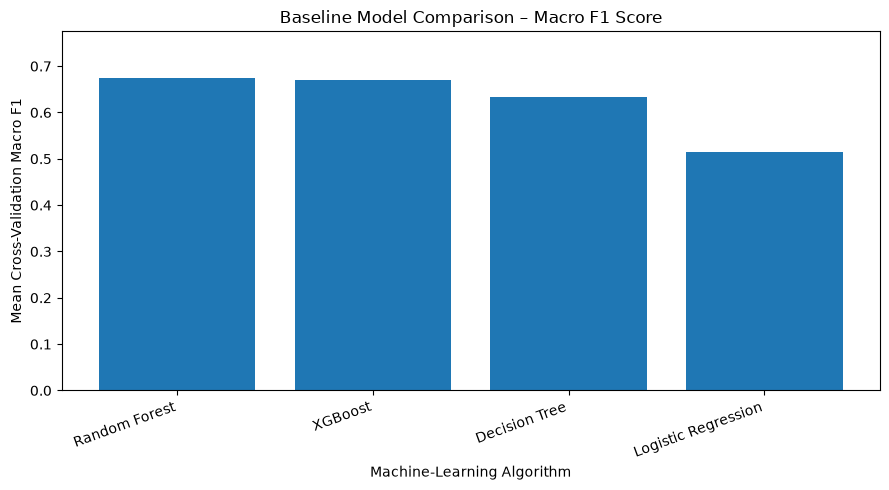

In [16]:
plt.figure(figsize=(9, 5))

plt.bar(
    baseline_results_df["Model"],
    baseline_results_df["CV Macro F1"]
)

plt.title("Baseline Model Comparison – Macro F1 Score")
plt.xlabel("Machine-Learning Algorithm")
plt.ylabel("Mean Cross-Validation Macro F1")

plt.xticks(
    rotation=20,
    ha="right"
)

plt.ylim(
    0,
    min(
        1.0,
        baseline_results_df["CV Macro F1"].max() + 0.1
    )
)

plt.tight_layout()
plt.show()

## 10. Training vs Validation Performance

Training Macro F1-score is compared with validation Macro F1-score to investigate possible overfitting.

A large difference between training and validation performance may indicate that a model is learning the training observations too closely and is not generalising as effectively to unseen data.

This comparison is particularly useful for tree-based models such as Decision Tree and Random Forest.

In [17]:
overfitting_analysis = baseline_results_df[
    [
        "Model",
        "Train Macro F1",
        "CV Macro F1"
    ]
].copy()

overfitting_analysis["F1 Gap"] = (
    overfitting_analysis["Train Macro F1"]
    - overfitting_analysis["CV Macro F1"]
)

overfitting_analysis[
    [
        "Train Macro F1",
        "CV Macro F1",
        "F1 Gap"
    ]
] = (
    overfitting_analysis[
        [
            "Train Macro F1",
            "CV Macro F1",
            "F1 Gap"
        ]
    ].round(4)
)

display(overfitting_analysis)

,Model,Train Macro F1,CV Macro F1,F1 Gap
0,Random Forest,0.9884,0.6751,0.3133
1,XGBoost,0.8008,0.6696,0.1311
2,Decision Tree,0.9885,0.6344,0.3541
3,Logistic Regression,0.5158,0.5140,0.0018


### 10.1 Interpretation of Training and Validation Performance

The comparison between training and cross-validation Macro F1-scores reveals different generalisation behaviour across the four algorithms.

The **Decision Tree shows the largest performance gap**, with a training Macro F1-score of 0.9885 compared with a validation Macro F1-score of 0.6344. This indicates substantial overfitting, where the unrestricted tree learns the training observations very closely but does not generalise equally well to unseen data.

The **Random Forest also shows considerable overfitting**, with a training Macro F1-score of 0.9884 and a validation Macro F1-score of 0.6751. Although Random Forest provides the strongest baseline validation performance, the large training-validation gap suggests that model complexity should be controlled during hyperparameter optimization.

**XGBoost shows a smaller generalisation gap**, with a training Macro F1-score of 0.8008 and a validation Macro F1-score of 0.6696. This indicates that XGBoost provides competitive validation performance while exhibiting less overfitting than the Random Forest and Decision Tree baselines.

The **Logistic Regression training and validation scores are almost identical**, at 0.5158 and 0.5140 respectively. However, both scores are comparatively low. This suggests underfitting rather than overfitting, indicating that the linear model is not sufficiently flexible to capture the complex relationships in the dataset.

These results make Random Forest and XGBoost the most appropriate candidates for further optimization.

## 11. Identify the Best Baseline Model

The baseline model with the highest mean cross-validation Macro F1-score is identified automatically.

This model is considered the strongest baseline according to the primary evaluation metric. However, this does not yet represent the final model because hyperparameter tuning, imbalance handling, and further optimization will be investigated during Stage 7.

In [18]:
best_baseline_name = (
    baseline_results_df
    .iloc[0]["Model"]
)

best_baseline_macro_f1 = (
    baseline_results_df
    .iloc[0]["CV Macro F1"]
)

print("Best baseline model:")
print(best_baseline_name)

print(
    "\nCross-validation Macro F1:",
    round(best_baseline_macro_f1, 4)
)

Best baseline model:
Random Forest

Cross-validation Macro F1: 0.6751


## 12. Detailed Cross-Validated Analysis of the Best Baseline Model

The strongest baseline model is analysed in more detail using out-of-fold predictions.

Out-of-fold predictions are generated by training the model repeatedly on different training folds and predicting observations that were not included in each corresponding training fold.

This provides class-specific precision, recall, and F1-score estimates without using the independent test dataset.

In [22]:
best_baseline_pipeline = model_pipelines[
    best_baseline_name
]

best_oof_predictions = cross_val_predict(
    estimator=best_baseline_pipeline,
    X=X_train_model,
    y=y_train_encoded,
    cv=cv_strategy,
    method="predict",
    n_jobs=1
)

print(
    "Out-of-fold predictions generated:",
    len(best_oof_predictions)
)

Out-of-fold predictions generated: 47520


### 12.1 Classification Report

Class-level precision, recall, and F1-score are examined for the best baseline model.

Particular attention is given to the `functional needs repair` class because it is the least represented class in the dataset.

In [23]:
print(
    classification_report(
        y_train_encoded,
        best_oof_predictions,
        labels=np.arange(
            len(label_encoder.classes_)
        ),
        target_names=label_encoder.classes_,
        digits=4,
        zero_division=0
    )
)

                         precision    recall  f1-score   support

             functional     0.8032    0.8675    0.8341     25807
functional needs repair     0.5038    0.3246    0.3948      3454
         non functional     0.8157    0.7783    0.7966     18259

               accuracy                         0.7938     47520
              macro avg     0.7076    0.6568    0.6752     47520
           weighted avg     0.7862    0.7938    0.7878     47520



### Interpretation of Class-Level Performance

The class-level results show that the baseline Random Forest performs considerably better for the two larger target classes than for the minority `functional needs repair` class.

For the `functional` class, the model achieved a precision of 0.8032, recall of 0.8675, and F1-score of 0.8341. This indicates strong performance in identifying operational waterpoints.

For the `non functional` class, the model achieved a precision of 0.8157, recall of 0.7783, and F1-score of 0.7966, demonstrating similarly strong classification performance.

However, performance for the minority `functional needs repair` class was substantially weaker. The model achieved a precision of 0.5038, recall of only 0.3246, and F1-score of 0.3948.

The recall of 0.3246 indicates that the model identifies only about 32.5% of the actual waterpoints requiring repair, while a large proportion of these cases are predicted as one of the other classes. This is particularly important for the proposed maintenance-support system because failing to identify waterpoints that require repair could prevent maintenance teams from responding before further deterioration occurs.

The difference between the strong performance of the majority classes and the low recall of the minority class indicates that class imbalance remains an important modelling issue.

Although the baseline Random Forest achieved an overall accuracy of approximately 79.4%, the class-level results demonstrate why accuracy alone is insufficient for evaluating this problem.

Therefore, Stage 7 optimization should investigate techniques that improve minority-class detection while maintaining acceptable performance across all three classes.

### 12.2 Store Class-Level Performance

The classification report is converted into a structured table so that class-specific results can be documented and compared during later optimization experiments.

In [24]:
classification_report_dict = classification_report(
    y_train_encoded,
    best_oof_predictions,
    labels=np.arange(
        len(label_encoder.classes_)
    ),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

classification_report_df = (
    pd.DataFrame(
        classification_report_dict
    )
    .transpose()
)

display(
    classification_report_df.round(4)
)

,precision,recall,f1-score,support
functional,0.8032,0.8675,0.8341,25807.0000
functional needs repair,0.5038,0.3246,0.3948,3454.0000
non functional,0.8157,0.7783,0.7966,18259.0000
accuracy,0.7938,0.7938,0.7938,0.7938
macro avg,0.7076,0.6568,0.6752,47520.0000
weighted avg,0.7862,0.7938,0.7878,47520.0000


## 13. Confusion Matrix of the Best Baseline Model

A confusion matrix is used to examine which target classes are correctly classified and which classes are commonly confused.

This analysis is particularly useful for determining whether `functional needs repair` waterpoints are incorrectly predicted as either `functional` or `non functional`.

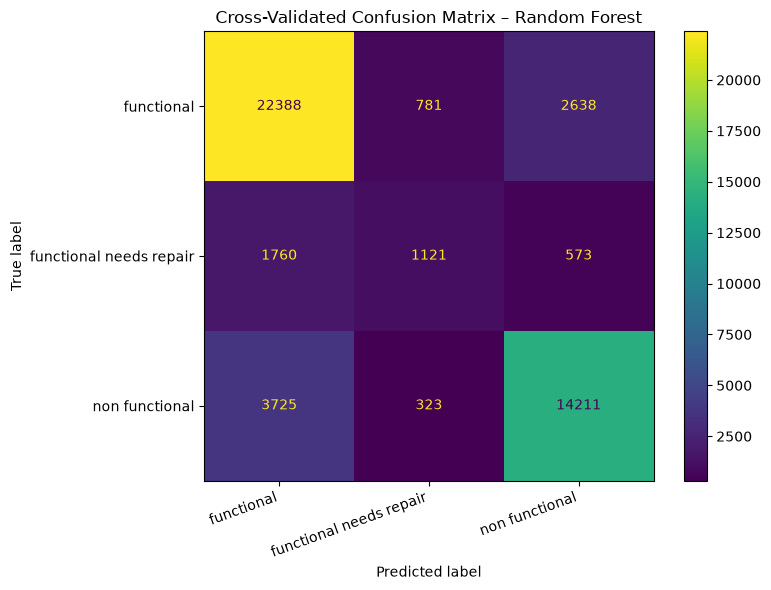

In [25]:
cm = confusion_matrix(
    y_train_encoded,
    best_oof_predictions,
    labels=np.arange(
        len(label_encoder.classes_)
    )
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

fig, ax = plt.subplots(
    figsize=(8, 6)
)

disp.plot(
    ax=ax,
    values_format="d"
)

plt.title(
    f"Cross-Validated Confusion Matrix – {best_baseline_name}"
)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()
plt.show()

### 13.1 Interpretation of the Confusion Matrix

The cross-validated confusion matrix provides further evidence that the baseline Random Forest performs differently across the three waterpoint-status classes.

For the `functional` class, 22,388 out of 25,807 observations were correctly classified. Most functional waterpoints were therefore identified successfully, although 2,638 were incorrectly classified as `non functional` and 781 as `functional needs repair`.

For the `non functional` class, 14,211 out of 18,259 observations were correctly classified. However, 3,725 non-functional waterpoints were incorrectly predicted as `functional`, while 323 were predicted as `functional needs repair`.

The greatest weakness occurs for the minority `functional needs repair` class. Out of 3,454 actual repair-needed waterpoints, only 1,121 were correctly classified.

A total of 1,760 repair-needed waterpoints were incorrectly classified as `functional`, representing approximately 51% of the actual repair class. A further 573 were incorrectly classified as `non functional`.

This is an important operational issue because a waterpoint requiring maintenance but predicted as fully functional may not be prioritised for inspection or repair. Such false-negative behaviour could allow a deteriorating waterpoint to remain untreated until it becomes completely non-functional.

The confusion matrix therefore confirms that overall accuracy alone does not adequately represent model quality for this problem. Improving the detection of the `functional needs repair` class should be an important objective during model optimization.

## 14. Baseline Model Observations

The baseline experiments provide an initial comparison of four different classification approaches.

The models should be interpreted using several criteria rather than accuracy alone.

Important considerations include:

- overall predictive accuracy,
- Macro F1-score,
- Macro Recall,
- performance on the minority `functional needs repair` class,
- differences between training and validation performance,
- computational cost,
- evidence of overfitting.

The model with the highest Macro F1-score provides the strongest baseline performance across the three classes. However, poor recall or F1-score for the minority class may indicate that class-imbalance handling should be investigated during optimization.

A large gap between training and validation scores may indicate overfitting and suggest that regularisation or model-complexity controls should be investigated.

No final model is selected at this stage. The strongest baseline models will proceed to Stage 7 for optimization and further comparison.

## 15. Candidate Models for Optimization

The two strongest baseline algorithms according to cross-validation Macro F1-score are selected as candidates for Stage 7 optimization.

Further experiments will investigate hyperparameter tuning and appropriate class-imbalance strategies before the final model is selected.

In [26]:
optimization_candidates = (
    baseline_results_df
    .head(2)["Model"]
    .tolist()
)

print("Models selected for Stage 7 optimization:")

for model_name in optimization_candidates:
    print("-", model_name)

Models selected for Stage 7 optimization:
- Random Forest
- XGBoost


## 16. Save Baseline Experiment Results

The baseline cross-validation results and class-level performance of the strongest baseline model are saved as experiment evidence.

These files can later be used to compare baseline and optimized models during Stage 7.

In [27]:
results_dir = Path("../results")
results_dir.mkdir(
    parents=True,
    exist_ok=True
)

baseline_results_path = (
    results_dir /
    "baseline_model_results.csv"
)

baseline_results_df.to_csv(
    baseline_results_path,
    index=False
)

classification_report_path = (
    results_dir /
    "best_baseline_classification_report.csv"
)

classification_report_df.to_csv(
    classification_report_path
)

print("Baseline results saved to:")
print(baseline_results_path)

print("\nClassification report saved to:")
print(classification_report_path)

Baseline results saved to:
..\results\baseline_model_results.csv

Classification report saved to:
..\results\best_baseline_classification_report.csv


In [28]:
models_dir = Path("../models")
models_dir.mkdir(
    parents=True,
    exist_ok=True
)

label_encoder_path = (
    models_dir /
    "label_encoder.joblib"
)

joblib.dump(
    label_encoder,
    label_encoder_path
)

print(
    "Label encoder saved to:",
    label_encoder_path
)

Label encoder saved to: ..\models\label_encoder.joblib


## 17. Save the Best Baseline Model

The strongest baseline pipeline is fitted using the complete training dataset and saved as an experimental model.

This model is not considered the final project model. It provides a baseline artifact that can later be compared against optimized models developed during Stage 7.

The independent test dataset remains unused.

In [29]:
best_baseline_pipeline = clone(
    model_pipelines[
        best_baseline_name
    ]
)

best_baseline_pipeline.fit(
    X_train_model,
    y_train_encoded
)

baseline_model_path = (
    models_dir /
    "best_baseline_model.joblib"
)

joblib.dump(
    best_baseline_pipeline,
    baseline_model_path
)

print(
    "Best baseline model:",
    best_baseline_name
)

print(
    "Saved to:",
    baseline_model_path
)

Best baseline model: Random Forest
Saved to: ..\models\best_baseline_model.joblib


## 18. Stage 6 Summary

Four machine-learning algorithms were developed and systematically compared:

- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost

All algorithms were evaluated using 5-fold Stratified K-Fold cross-validation.

Preprocessing was included inside each model pipeline so that numerical imputation, scaling, and categorical encoding were fitted only on the training portion of each cross-validation fold. This prevented validation data from influencing preprocessing parameters.

The models were evaluated using:

- Accuracy
- Macro F1-score
- Weighted F1-score
- Macro Recall

Macro F1-score was used as the primary comparison metric because the target classes are imbalanced and the `functional needs repair` class represents a relatively small proportion of the dataset.

Training and validation Macro F1-scores were also compared to investigate possible model overfitting.

The highest-performing baseline model was analysed further using out-of-fold predictions, a class-level classification report, and a confusion matrix.

The two strongest baseline algorithms were identified as candidates for Stage 7 optimization.

Class-balancing approaches such as class weighting and SMOTE/SMOTENC were intentionally not applied during baseline development. Their effect will be investigated during optimization so that improvements can be compared against the original baseline models.

The independent test dataset has remained untouched and will be reserved for evaluation of the final selected model.